# Medical Waste Data Visualization

Issue #5 — MED-WASTE-SEGREGATION (Data Analytics & Visualization)

**Input:** `data/processed/medical_waste_cleaned.csv` (Issue #3), with numbers from `src/analytics.py` (Issue #4)
**Outputs:** eight charts exported as PNG and SVG to `reports/figures/`, and `reports/visualization_summary.md`

The chart code lives in `src/visualization.py`. This notebook draws each chart, explains how to read it, exports all files and checks them.

> The dataset appears to be simulated (see `docs/data_sources.md`). The charts describe this file and demonstrate the workflow. They are not evidence about real hospitals.

| # | Chart | Question it answers |
|---|---|---|
| 1 | Records per waste category | How are records spread across waste types? |
| 2 | Records per ward | Which wards produce the records? |
| 3 | Weight distribution | What does a typical record weigh? |
| 4 | Weight by category | Do categories differ in weight? |
| 5 | Misclassification by category | Which categories are misclassified most, and how sure are we? |
| 6 | Alert rate by fill level | When do alerts fire? |
| 7 | Records per day | Is there a trend over the month? |
| 8 | Weekday and hour pattern | Are some days or hours busier? |

## 0. Setup

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import analytics as an
from src import visualization as viz

df = viz.load_visualization_data(viz.DEFAULT_DATA)
results = an.run_analysis(df)
print("Records loaded:", len(df))
print("Charts available:", len(viz.CHARTS))

Records loaded: 1482
Charts available: 8


## 1. Records per waste category

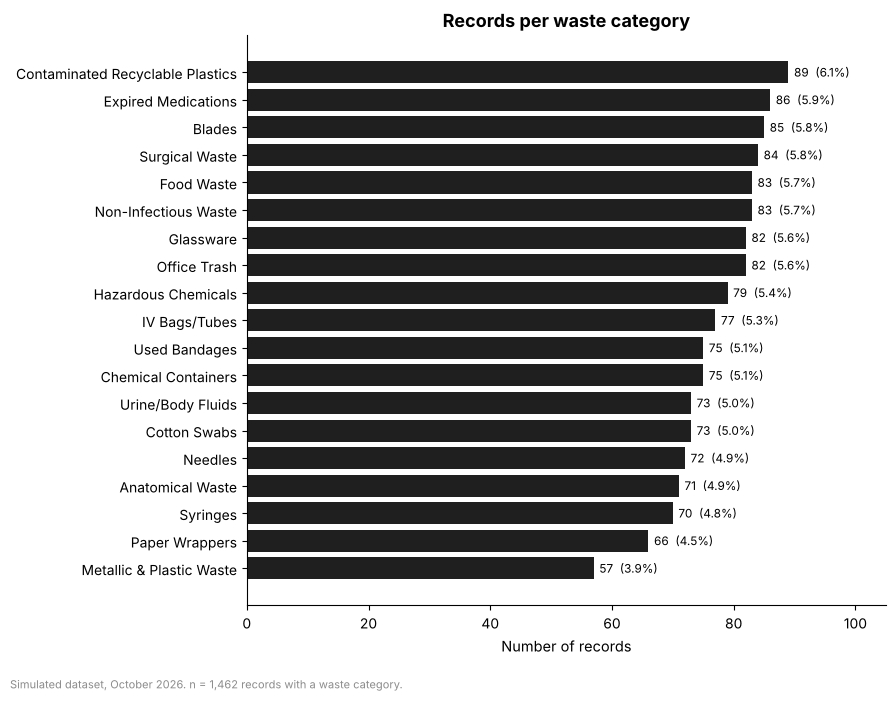

In [2]:
fig = viz.CHARTS[0][1](df, results)
plt.show()

**How to read it:** each bar is the number of records for one waste category, with its share of all categorised records. Counts run from 57 to 89, so no category dominates and none is missing.

## 2. Records per ward

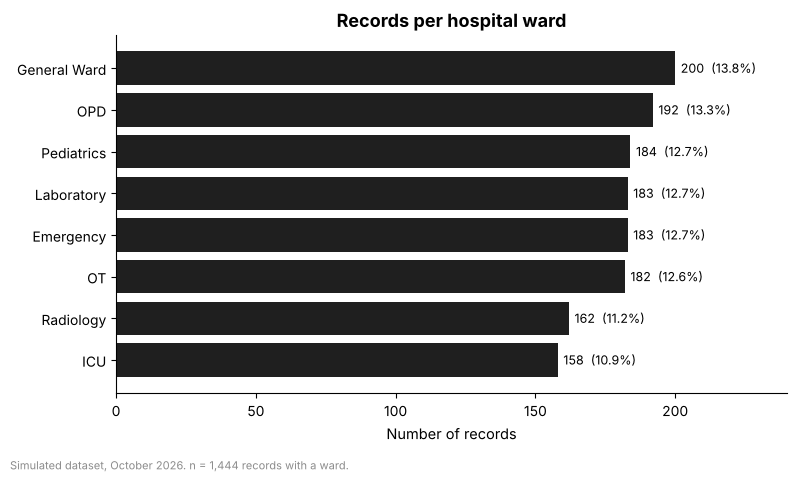

In [3]:
fig = viz.CHARTS[1][1](df, results)
plt.show()

**How to read it:** each bar is the number of records from one hospital ward. The eight wards contribute between about 11% and 14% each.

## 3. Weight distribution

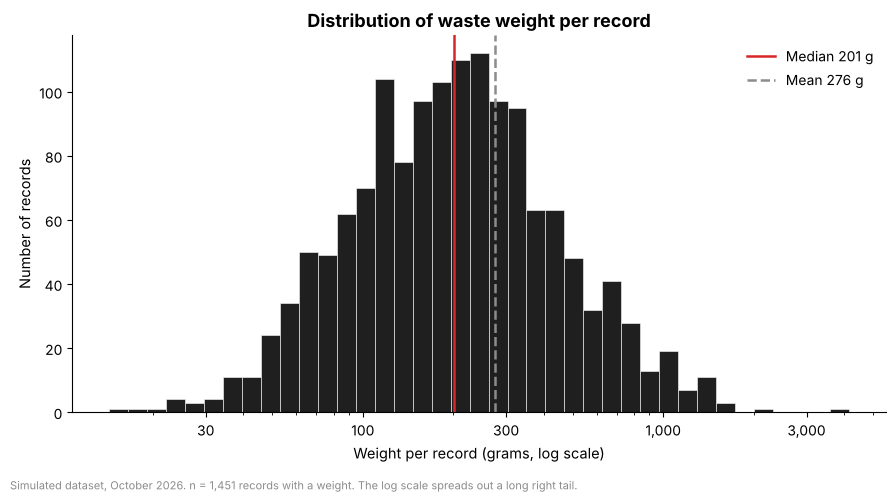

In [4]:
fig = viz.CHARTS[2][1](df, results)
plt.show()

**How to read it:** most records weigh a few hundred grams, with a long tail of heavier items. Because of that tail the mean (276 g) sits well above the median (201 g). The axis is logarithmic, so equal distances mean equal ratios, not equal grams. Medians are therefore the better summary for weight.

## 4. Weight by waste category

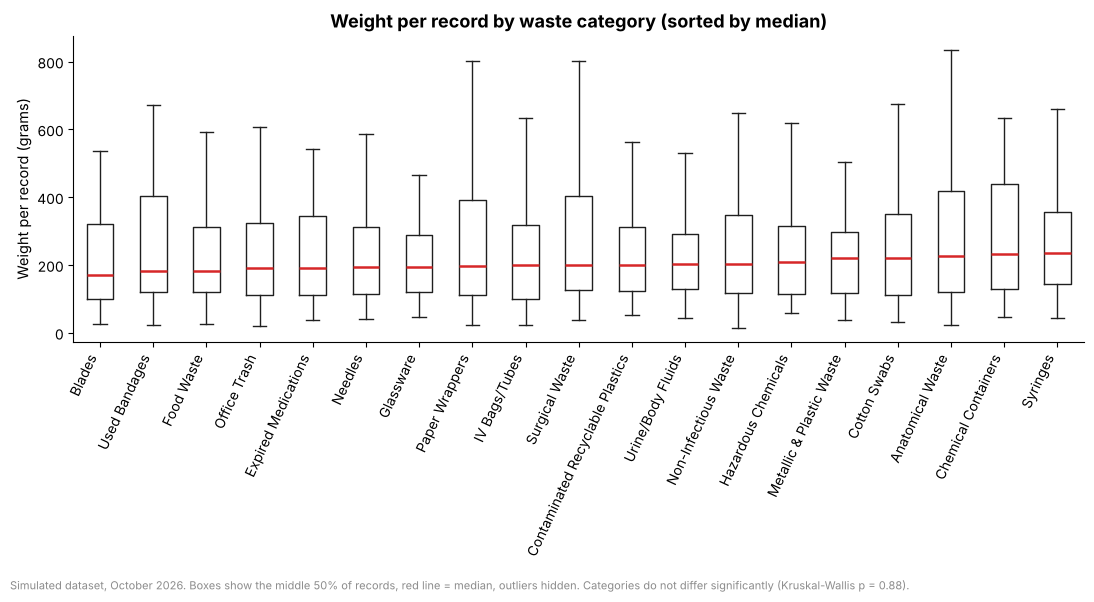

In [5]:
fig = viz.CHARTS[3][1](df, results)
plt.show()

**How to read it:** each box covers the middle 50% of a category's records, and the red line is its median. The boxes overlap heavily, and a Kruskal-Wallis test finds no significant difference between categories. Outliers are hidden here for readability; chart 3 shows the full range.

## 5. Misclassification by category

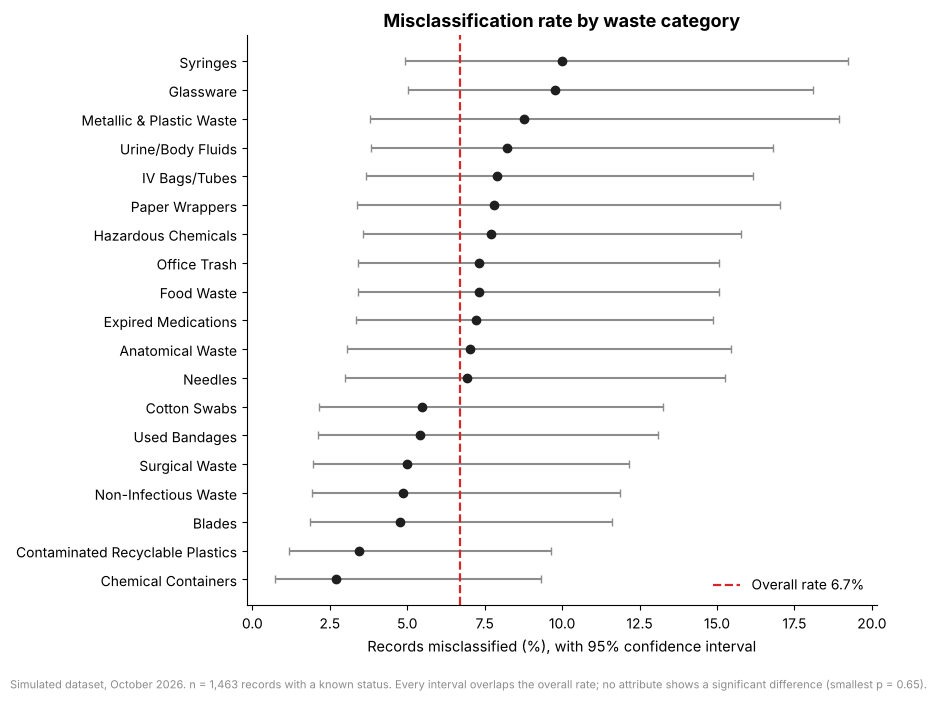

In [6]:
fig = viz.CHARTS[4][1](df, results)
plt.show()

**How to read it:** each dot is a category's misclassification rate and the grey line is its 95% confidence interval. The red dashed line is the overall rate. Every interval overlaps the overall rate, so Syringes and Glassware at the top are not reliably worse than the rest. The intervals are wide because each category has only about 55 to 90 records.

## 6. Alert rate by fill level

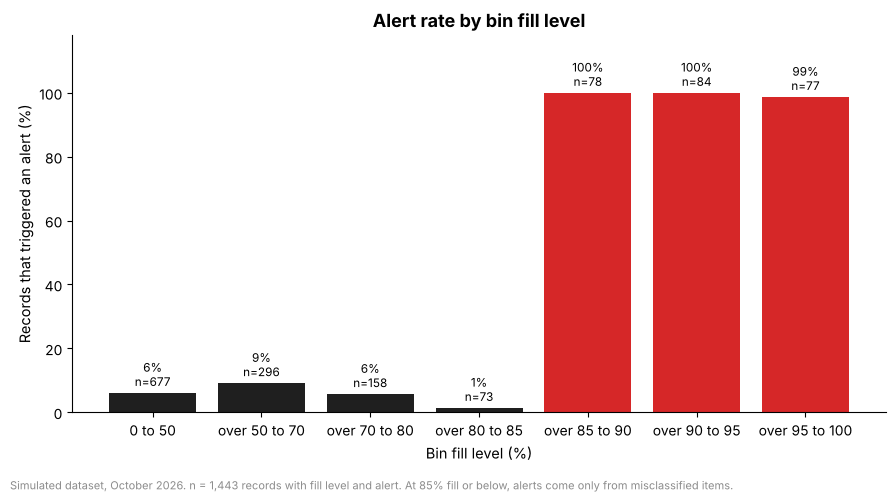

In [7]:
fig = viz.CHARTS[5][1](df, results)
plt.show()

**How to read it:** alerts are rare below 85% fill and almost universal above it. The low-fill alerts come from misclassified items. This is a pattern in the data, not a documented rule.

## 7. Records per day

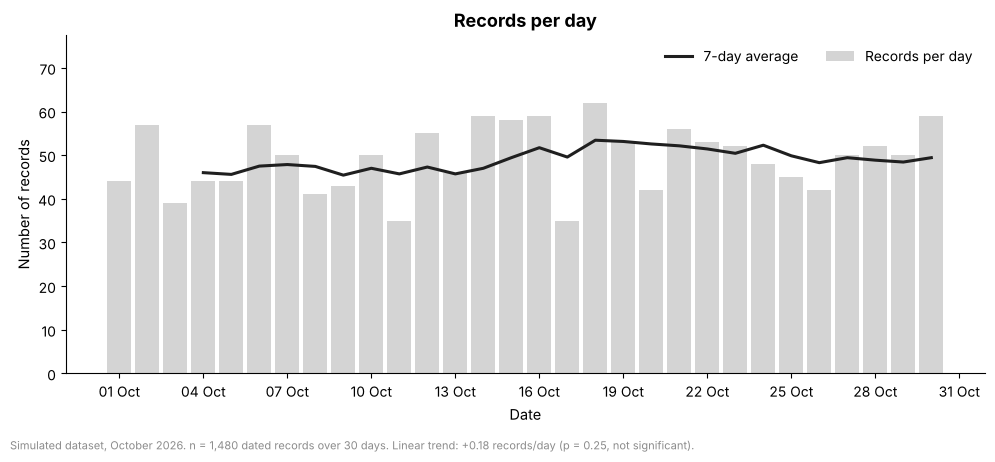

In [8]:
fig = viz.CHARTS[6][1](df, results)
plt.show()

**How to read it:** grey bars are daily counts and the dark line is a 7-day average. Activity stays in a narrow band with no significant upward or downward trend.

## 8. Weekday and hour pattern

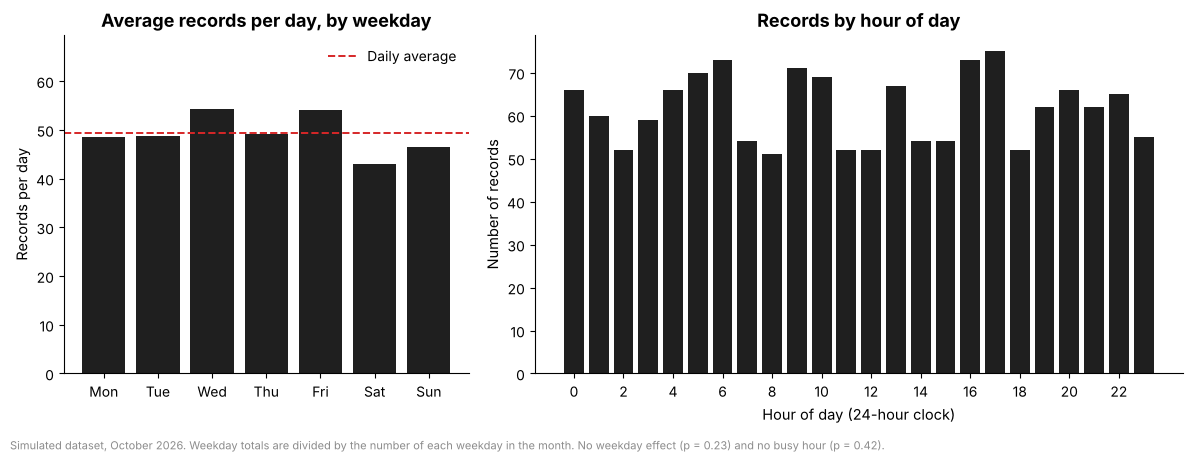

In [9]:
fig = viz.CHARTS[7][1](df, results)
plt.show()

**How to read it:** the left panel shows the average number of records per day for each weekday. It divides by how many of that weekday fall in the month (a month has five of some weekdays and four of others). The right panel counts records per hour. Neither panel shows a significant pattern.

## 9. Export all charts as PNG and SVG

In [10]:
out = viz.DEFAULT_OUT
paths = viz.generate_all_charts(df, out, formats=("png", "svg"), results=results)
print(f"Exported {len(paths)} files to {out.relative_to(ROOT)}")
assert len(paths) == len(viz.CHARTS) * 2
for p in paths:
    print(" ", p.relative_to(ROOT))

Exported 16 files to reports/figures
  reports/figures/01_waste_category_counts.png
  reports/figures/01_waste_category_counts.svg
  reports/figures/02_ward_distribution.png
  reports/figures/02_ward_distribution.svg
  reports/figures/03_weight_distribution.png
  reports/figures/03_weight_distribution.svg
  reports/figures/04_weight_by_category.png
  reports/figures/04_weight_by_category.svg
  reports/figures/05_misclassification_by_category.png
  reports/figures/05_misclassification_by_category.svg
  reports/figures/06_alert_rate_by_fill_level.png
  reports/figures/06_alert_rate_by_fill_level.svg
  reports/figures/07_daily_records.png
  reports/figures/07_daily_records.svg
  reports/figures/08_weekday_and_hour.png
  reports/figures/08_weekday_and_hour.svg


## 10. Validate the exports

In [11]:
checks = viz.validate_exports(paths)
display(checks)
assert checks["passed"].all(), "An export is missing, empty or invalid"
print(f"All {len(checks)} files exist, are non-empty and are valid PNG or SVG.")

,file,size_kb,passed,details
0,01_waste_category_counts.png,155.6,True,valid PNG header
1,01_waste_category_counts.svg,88.6,True,valid SVG XML
2,02_ward_distribution.png,69.8,True,valid PNG header
3,02_ward_distribution.svg,52.0,True,valid SVG XML
4,03_weight_distribution.png,65.5,True,valid PNG header
5,03_weight_distribution.svg,60.6,True,valid SVG XML
6,04_weight_by_category.png,145.1,True,valid PNG header
7,04_weight_by_category.svg,103.0,True,valid SVG XML
8,05_misclassification_by_category.png,155.5,True,valid PNG header
9,05_misclassification_by_category.svg,95.6,True,valid SVG XML


All 16 files exist, are non-empty and are valid PNG or SVG.


## 11. Write the summary report

In [12]:
viz.DEFAULT_SUMMARY.write_text(viz.build_summary_markdown(df, results), encoding="utf-8")
print("Wrote:", viz.DEFAULT_SUMMARY.relative_to(ROOT))

Wrote: reports/visualization_summary.md


## Summary

* Eight charts cover distributions, comparisons, outcomes, alerts and time patterns, all drawn from the cleaned data and the Issue #4 results.
* Each chart carries a footer with the number of records used and the simulated-data caveat.
* Uncertainty is shown where groups are small (confidence intervals), and skewed data uses a log scale or medians.
* All 16 exported files exist, are non-empty and are valid PNG or SVG.
* Run `python -m src.visualization` to regenerate everything without the notebook.